In [2]:
import os

dataset_path = "/kaggle/input"

for folder in os.listdir(dataset_path):
    print(folder)

datasets


In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    print("Subfolders:", dirs[:10])
    print("Sample files:", files[:5])

    if root.count(os.sep) >= 4:
        dirs[:] = []

Folder: /kaggle/input
Subfolders: ['datasets']
Sample files: []
Folder: /kaggle/input/datasets
Subfolders: ['gti-upm']
Sample files: []
Folder: /kaggle/input/datasets/gti-upm
Subfolders: ['leapgestrecog']
Sample files: []


In [4]:
import os

dataset_path = "/kaggle/input/datasets/gti-upm/leapgestrecog"

print(os.listdir(dataset_path))

['leapGestRecog', 'leapgestrecog']


In [5]:
import os

for folder in os.listdir(dataset_path):
    path = os.path.join(dataset_path, folder)
    print(folder, "->", os.listdir(path)[:10])

leapGestRecog -> ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09']
leapgestrecog -> ['leapGestRecog']


In [6]:
import os

data_path = os.path.join(dataset_path, "leapGestRecog")

for person in sorted(os.listdir(data_path)):
    person_path = os.path.join(data_path, person)
    print(person, ":", os.listdir(person_path))

00 : ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
01 : ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
02 : ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
03 : ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
04 : ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
05 : ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
06 : ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
07 : ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
08 : ['01_palm', '02_l',

In [7]:
import os

gesture_counts = {}

for gesture in sorted(os.listdir(os.path.join(data_path, "00"))):
    gesture_path = os.path.join(data_path, "00", gesture)

    count = len([
        file for file in os.listdir(gesture_path)
        if file.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])

    gesture_counts[gesture] = count

for gesture, count in gesture_counts.items():
    print(gesture, ":", count)

print("\nTotal images:", sum(gesture_counts.values()))

01_palm : 200
02_l : 200
03_fist : 200
04_fist_moved : 200
05_thumb : 200
06_index : 200
07_ok : 200
08_palm_moved : 200
09_c : 200
10_down : 200

Total images: 2000


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [9]:
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [10]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [11]:
import os
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

IMG_SIZE = 64

images = []
labels = []

for person in sorted(os.listdir(data_path)):
    person_path = os.path.join(data_path, person)

    for gesture in sorted(os.listdir(person_path)):
        gesture_path = os.path.join(person_path, gesture)

        for file in os.listdir(gesture_path):
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(gesture_path, file)

                img = load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE), color_mode='grayscale')
                img = img_to_array(img) / 255.0

                images.append(img)
                labels.append(gesture)

X = np.array(images, dtype=np.float32)
y = np.array(labels)

print("Image data shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of classes:", len(np.unique(y)))

Image data shape: (20000, 64, 64, 1)
Labels shape: (20000,)
Number of classes: 10


In [12]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Gesture classes:", encoder.classes_)
print("Encoded labels:", np.unique(y))

Gesture classes: ['01_palm' '02_l' '03_fist' '04_fist_moved' '05_thumb' '06_index' '07_ok'
 '08_palm_moved' '09_c' '10_down']
Encoded labels: [0 1 2 3 4 5 6 7 8 9]


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (14000, 64, 64, 1)
Validation: (3000, 64, 64, 1)
Testing: (3000, 64, 64, 1)


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,914 (2.61 MB)

 Trainable params: 683,914 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [26]:
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9967 - loss: 0.0101 - val_accuracy: 1.0000 - val_loss: 1.3557e-06
Epoch 2/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9976 - loss: 0.0078 - val_accuracy: 1.0000 - val_loss: 1.6577e-06
Epoch 3/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9997 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: 1.4841e-04
Epoch 4/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9994 - loss: 0.0017 - val_accuracy: 1.0000 - val_loss: 1.4930e-04


In [27]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [28]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997 - loss: 3.5594e-04
Test Loss: 0.0003559437463991344
Test Accuracy: 99.9666690826416 %


94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


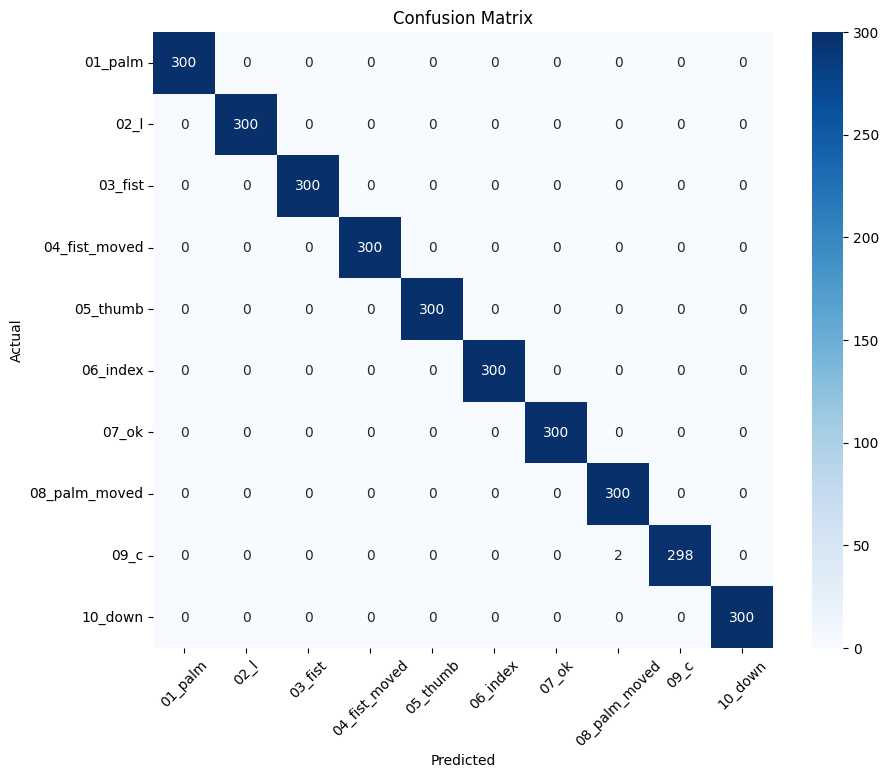

               precision    recall  f1-score   support

      01_palm       1.00      1.00      1.00       300
         02_l       1.00      1.00      1.00       300
      03_fist       1.00      1.00      1.00       300
04_fist_moved       1.00      1.00      1.00       300
     05_thumb       1.00      1.00      1.00       300
     06_index       1.00      1.00      1.00       300
        07_ok       1.00      1.00      1.00       300
08_palm_moved       0.99      1.00      1.00       300
         09_c       1.00      0.99      1.00       300
      10_down       1.00      1.00      1.00       300

     accuracy                           1.00      3000
    macro avg       1.00      1.00      1.00      3000
 weighted avg       1.00      1.00      1.00      3000



In [23]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_,
            cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

print(classification_report(
    y_test, y_pred, target_names=encoder.classes_
))

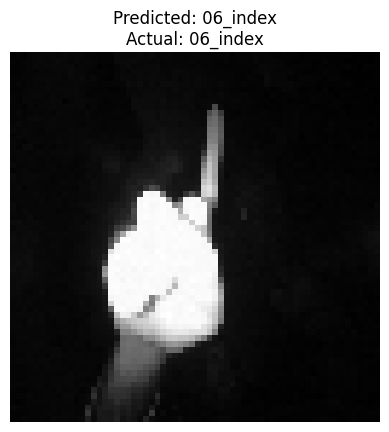

Confidence: 100.0 %


In [29]:
import random

index = random.randint(0, len(X_test) - 1)

prediction = model.predict(X_test[index:index+1], verbose=0)

predicted_class = np.argmax(prediction)
actual_class = y_test[index]

plt.imshow(X_test[index].squeeze(), cmap='gray')
plt.title(
    f"Predicted: {encoder.classes_[predicted_class]}\n"
    f"Actual: {encoder.classes_[actual_class]}"
)
plt.axis('off')
plt.show()

print("Confidence:", round(np.max(prediction) * 100, 2), "%")

In [37]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/ayyushii/hand-photo/WIN_20261105_21_19_24_Pro.jpg
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0001.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0002.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0003.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0004.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0005.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0006.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0007.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0008.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0009.png
/kaggle/input/datasets/gti-upm/leapgestrecog/leapGestRecog/00/01_palm/frame_00_01_0010.png
/kaggle/input/dat

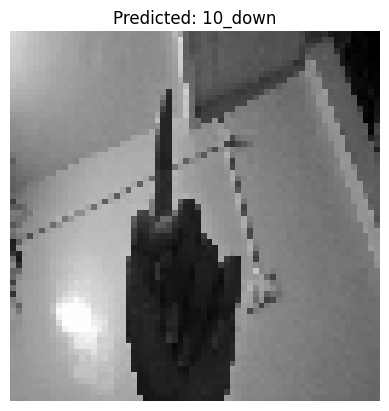

Confidence: 98.79 %


In [38]:
#My Own Hand Gesture Prediction
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

image_path = "/kaggle/input/datasets/ayyushii/hand-photo/WIN_20261105_21_19_24_Pro.jpg"

img = load_img(image_path, target_size=(64, 64), color_mode='grayscale')
img = img_to_array(img) / 255.0

img = np.expand_dims(img, axis=0)

prediction = model.predict(img, verbose=0)
predicted_class = np.argmax(prediction)

plt.imshow(img[0].squeeze(), cmap='gray')
plt.title(f"Predicted: {encoder.classes_[predicted_class]}")
plt.axis('off')
plt.show()

print("Confidence:", round(np.max(prediction) * 100, 2), "%")